# Finish-turning deflection model
Edit the **inputs** cell, then run the **model** cell. The model predicts the true vs nominal (radial) depth of cut for a cantilevered round bar, and the nominal depth of cut to command to hit a target diameter. Physics lives in `turning_model.py`.

In [1]:
# ---- Inputs (mm, N) ----
material = "al6061"        # "al6061" or "ti64"
rc_mm = 0.8                # tool nose radius
f_mm = 0.18                # feed per revolution
ap_mm = 0.25               # nominal radial depth of cut
d_mm = 16.0                # workpiece diameter before the pass
L_mm = 160.0               # overhang length
k_machine_N_mm = 50_000    # machine / tool-holder stiffness
target_d_mm = 15.5         # desired final diameter

material Al6061 (E=70 GPa)
rc=0.8 mm  f=0.18 mm/rev  d=16.0 mm  L=160.0 mm (L/D=10.0)
nominal ap        0.2500 mm
true ap           0.0936 mm  (37% of nominal)
deflection        156.4 um  (beam 155.8 + machine 0.5)
zero-defl. dia.   15.5000 mm
predicted dia.    15.8127 mm  (oversize 312.7 um)
forces            Fc 34.8 N   Fradial 25.7 N   Faxial 7.3 N
engaged arc       -6.45 to 28.00 deg, h_avg 52.3 um
rpm 1194  torque 0.28 N*m  power 35 W
kinematic Ra 1.69 um

pass  deflection [um]  % of nominal ap
   1            299.5            120%
   2            190.0             76%
   3            155.0             62%
   4            156.4             63%
   5            156.4             63%
   6            156.4             63%

Target dia 15.5 mm -> command ap = 0.5495 mm (true ap 0.2500 mm, final dia 15.5000 mm)


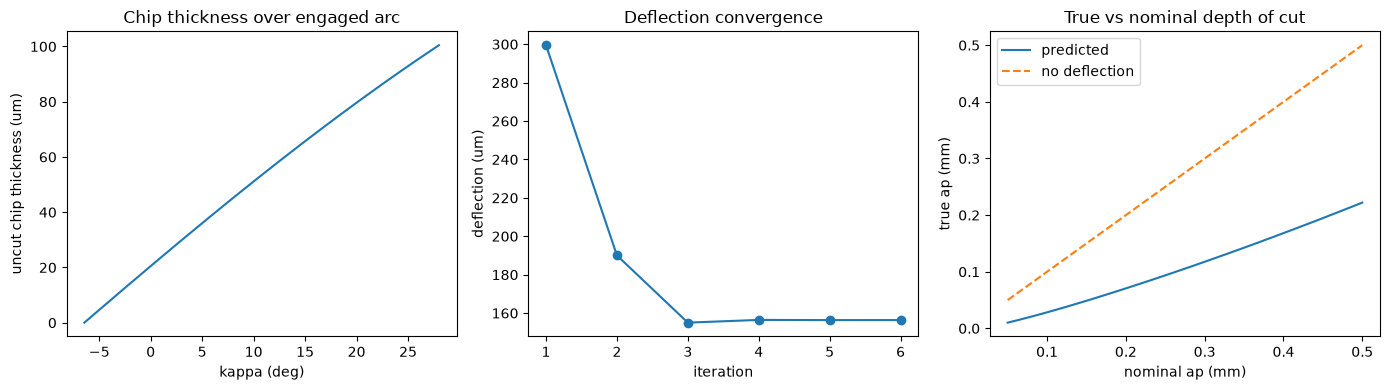

In [2]:
import turning_model as tm

inp = tm.Inputs(**tm.MATERIALS[material], rc_mm=rc_mm, f_mm=f_mm, ap_mm=ap_mm,
                d_mm=d_mm, L_mm=L_mm, k_machine_N_mm=k_machine_N_mm)
res = tm.solve_deflection(inp)
print(tm.report(inp, res))

# Deflection iteration table
print("\npass  deflection [um]  % of nominal ap")
for i, d in enumerate(res.history_mm, 1):
    print(f"{i:>4}  {d * 1000:>15.1f}  {d / inp.ap_mm:>14.0%}")

# Nominal ap to command so the deflected cut lands on the target diameter
ap_cmd, res_t = tm.solve_nominal_ap(inp, target_d_mm)
print(f"\nTarget dia {target_d_mm} mm -> command ap = {ap_cmd:.4f} mm "
      f"(true ap {res_t.ap_true_mm:.4f} mm, final dia {res_t.d_final_mm:.4f} mm)")

tm.plot(inp, res)